In [1]:
# Experiment 08 — Quantum Key Distribution Using BB84 Protocol

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

In [3]:
# Generate random bits and measurement bases
rng = np.random.default_rng(42)

n = 32

alice_bits = rng.integers(0, 2, n)
alice_bases = rng.integers(0, 2, n)
bob_bases = rng.integers(0, 2, n)

print("Alice Bits: ", alice_bits)
print("Alice Bases:", alice_bases)
print("Bob Bases:  ", bob_bases)

Alice Bits:  [0 1 1 0 0 1 0 1 0 0 1 1 1 1 1 1 1 0 1 0 1 0 0 1 1 1 0 1 1 0 0 0]
Alice Bases: [0 1 1 0 1 1 0 1 0 1 1 0 0 1 0 1 1 1 1 0 0 0 0 0 1 0 1 1 1 1 0 1]
Bob Bases:   [0 0 1 0 0 0 1 0 0 0 1 0 0 0 1 1 1 0 0 1 1 1 0 0 1 1 0 1 1 0 1 0]


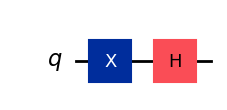

In [4]:
# Encode one bit using Alice's selected basis
def encode_bit(bit, basis):
    qc = QuantumCircuit(1)

    if bit == 1:
        qc.x(0)

    if basis == 1:
        qc.h(0)

    return qc

# Display an example encoding circuit
example = encode_bit(1, 1)

display(example.draw("mpl"))

In [5]:
# Measure a qubit using the selected basis
simulator = AerSimulator()

def measure_bit(qc, basis):
    circuit = qc.copy()

    if basis == 1:
        circuit.h(0)

    circuit.measure_all()

    result = simulator.run(
        transpile(circuit, simulator),
        shots=1
    ).result()

    return int(next(iter(result.get_counts())))

In [6]:
# Alice sends encoded qubits to Bob
bob_bits = []

for i in range(n):
    qc = encode_bit(alice_bits[i], alice_bases[i])

    measured_bit = measure_bit(qc, bob_bases[i])
    bob_bits.append(measured_bit)

bob_bits = np.array(bob_bits)

print("Alice Bits:", alice_bits)
print("Bob Bits:  ", bob_bits)

Alice Bits: [0 1 1 0 0 1 0 1 0 0 1 1 1 1 1 1 1 0 1 0 1 0 0 1 1 1 0 1 1 0 0 0]
Bob Bits:   [0 0 1 0 1 1 0 1 0 1 1 1 1 0 0 1 1 0 0 0 1 0 0 1 1 0 0 1 1 0 0 0]


In [7]:
# Keep positions where Alice and Bob used the same basis
matching_bases = alice_bases == bob_bases

alice_key = alice_bits[matching_bases]
bob_key = bob_bits[matching_bases]

print("Matching Bases:", np.sum(matching_bases))
print("Alice Key:", alice_key)
print("Bob Key:  ", bob_key)
print("Keys Match:", np.array_equal(alice_key, bob_key))

Matching Bases: 14
Alice Key: [0 1 0 0 1 1 1 1 1 0 1 1 1 1]
Bob Key:   [0 1 0 0 1 1 1 1 1 0 1 1 1 1]
Keys Match: True


In [8]:
# Calculate the error rate in the sifted key
if len(alice_key) > 0:
    qber = np.mean(alice_key != bob_key)
else:
    qber = 0

print("Shared Key Length:", len(alice_key))
print("Quantum Bit Error Rate:", round(qber * 100, 2), "%")

Shared Key Length: 14
Quantum Bit Error Rate: 0.0 %


In [9]:
# Eve intercepts and measures each transmitted qubit
eve_bases = rng.integers(0, 2, n)

bob_bits_eve = []

for i in range(n):
    qc = encode_bit(alice_bits[i], alice_bases[i])

    # Eve measures the qubit
    eve_bit = measure_bit(qc, eve_bases[i])

    # Eve sends a newly encoded qubit to Bob
    forwarded = encode_bit(eve_bit, eve_bases[i])

    bob_bit = measure_bit(forwarded, bob_bases[i])
    bob_bits_eve.append(bob_bit)

bob_bits_eve = np.array(bob_bits_eve)

alice_key_eve = alice_bits[matching_bases]
bob_key_eve = bob_bits_eve[matching_bases]

print("Alice Key:", alice_key_eve)
print("Bob Key After Eve:", bob_key_eve)

Alice Key: [0 1 0 0 1 1 1 1 1 0 1 1 1 1]
Bob Key After Eve: [0 1 0 1 1 1 1 1 1 0 1 0 0 1]


In [10]:
# Calculate the error rate caused by Eve
if len(alice_key_eve) > 0:
    qber_eve = np.mean(alice_key_eve != bob_key_eve)
else:
    qber_eve = 0

print("QBER Without Eve:", round(qber * 100, 2), "%")
print("QBER With Eve:", round(qber_eve * 100, 2), "%")

QBER Without Eve: 0.0 %
QBER With Eve: 21.43 %


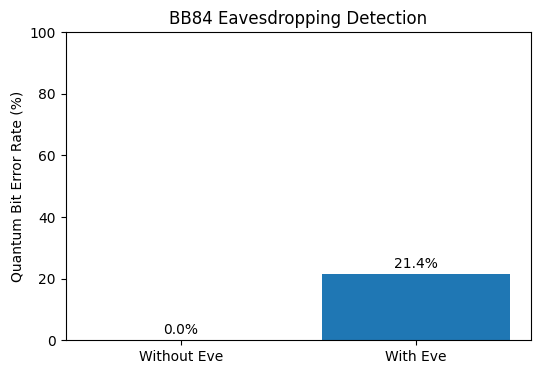

In [11]:
# Compare error rates with and without eavesdropping
labels = ["Without Eve", "With Eve"]
values = [qber * 100, qber_eve * 100]

plt.figure(figsize=(6, 4))
plt.bar(labels, values)

plt.ylabel("Quantum Bit Error Rate (%)")
plt.title("BB84 Eavesdropping Detection")
plt.ylim(0, 100)

for i, value in enumerate(values):
    plt.text(i, value + 2, f"{value:.1f}%", ha="center")

plt.show()